# Notebook 10 — U-Net Training

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Owners:** Vanshika and Nitanshu  
**Phase:** 2 (Deep Learning)  
**Objective:** Train a small U-Net on all 14,979 training maps with a masked, class-weighted loss, flips with the wind fix, dropout, weight decay and early stopping on validation PR-AUC.

---

## 1. Load data and normalise

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras

import src.dl_data as dd
import src.dl_model as dm

data_dir = "data/processed/dl"
train_X, train_Y = dd.load_split(data_dir, "train")
val_X, val_Y = dd.load_split(data_dir, "eval")

norm = dict(np.load("results/models/unet_norm.npz"))
train_X = dd.normalize(train_X, norm)
val_X = dd.normalize(val_X, norm)
print("train:", train_X.shape, "validation:", val_X.shape)


train: (14979, 64, 64, 13) validation: (1877, 64, 64, 13)


## 2. The U-Net
- **Encoder:** 3 levels of two 3×3 convolutions (16 → 32 → 64 filters), each followed by 2×2 max pooling (64 → 32 → 16 → 8 pixels).
- **Bottleneck:** 128 filters at 8×8 with dropout 0.2.
- **Decoder:** upsample back to 64×64; at each level the matching encoder output is joined in (**skip connection**), so fire-edge detail is not lost.
- **Output:** one sigmoid per pixel, which is the probability of fire tomorrow.

Batch normalisation after every convolution keeps training stable.

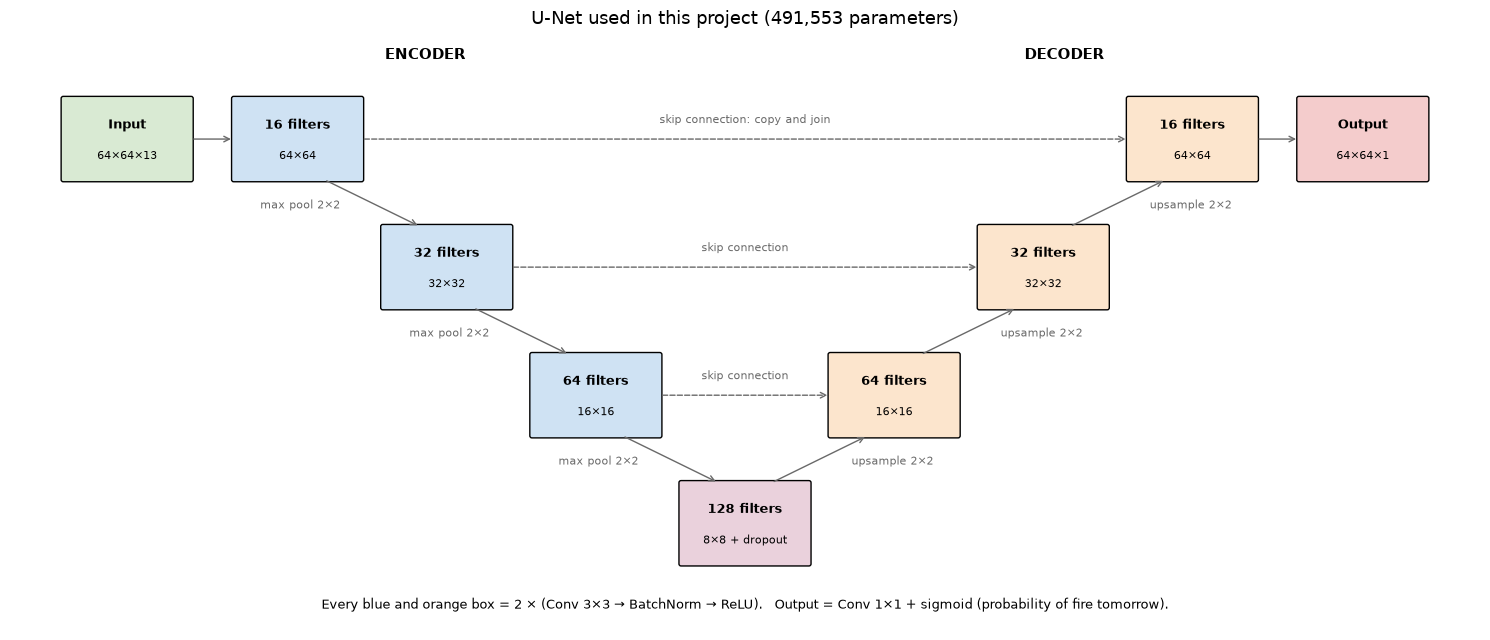

In [2]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(15, 6.5))
ax.set_xlim(-0.9, 12.9)
ax.set_ylim(-1.0, 4.6)
ax.axis("off")

BOX_W = 1.2
BOX_H = 0.76


def draw_box(x, y, title, size, color):
    ax.add_patch(patches.FancyBboxPatch((x - BOX_W / 2, y - BOX_H / 2), BOX_W, BOX_H, boxstyle="round,pad=0.02", facecolor=color, edgecolor="black"))
    ax.text(x, y + 0.13, title, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.text(x, y - 0.16, size, ha="center", va="center", fontsize=8)


def arrow(x1, y1, x2, y2, style="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", linestyle=style, color="dimgray"))


level_y = [3.6, 2.4, 1.2]
filters = [16, 32, 64]
sizes = ["64×64", "32×32", "16×16"]
enc_x = [1.8, 3.2, 4.6]
dec_x = [10.2, 8.8, 7.4]
mid_x = 6.0

draw_box(0.2, 3.6, "Input", "64×64×13", "#d9ead3")
draw_box(11.8, 3.6, "Output", "64×64×1", "#f4cccc")
draw_box(mid_x, 0.0, "128 filters", "8×8 + dropout", "#ead1dc")
arrow(0.2 + BOX_W / 2, 3.6, enc_x[0] - BOX_W / 2, 3.6)
arrow(dec_x[0] + BOX_W / 2, 3.6, 11.8 - BOX_W / 2, 3.6)

for i in range(3):
    draw_box(enc_x[i], level_y[i], f"{filters[i]} filters", sizes[i], "#cfe2f3")
    draw_box(dec_x[i], level_y[i], f"{filters[i]} filters", sizes[i], "#fce5cd")
    arrow(enc_x[i] + BOX_W / 2, level_y[i], dec_x[i] - BOX_W / 2, level_y[i], style="--")
    ax.text((enc_x[i] + dec_x[i]) / 2, level_y[i] + 0.15, "skip connection: copy and join" if i == 0 else "skip connection", ha="center", fontsize=8, color="dimgray")

down_from = [(enc_x[0], level_y[0]), (enc_x[1], level_y[1]), (enc_x[2], level_y[2])]
down_to = [(enc_x[1], level_y[1]), (enc_x[2], level_y[2]), (mid_x, 0.0)]
up_from = [(mid_x, 0.0), (dec_x[2], level_y[2]), (dec_x[1], level_y[1])]
up_to = [(dec_x[2], level_y[2]), (dec_x[1], level_y[1]), (dec_x[0], level_y[0])]
for (x1, y1), (x2, y2) in zip(down_from, down_to):
    arrow(x1 + 0.25, y1 - BOX_H / 2, x2 - 0.25, y2 + BOX_H / 2)
    ax.text((x1 + x2) / 2 - 0.3, (y1 + y2) / 2 - 0.05, "max pool 2×2", ha="right", fontsize=8, color="dimgray")
for (x1, y1), (x2, y2) in zip(up_from, up_to):
    arrow(x1 + 0.25, y1 + BOX_H / 2, x2 - 0.25, y2 - BOX_H / 2)
    ax.text((x1 + x2) / 2 + 0.3, (y1 + y2) / 2 - 0.05, "upsample 2×2", ha="left", fontsize=8, color="dimgray")

ax.text(3.0, 4.35, "ENCODER", ha="center", fontsize=11, fontweight="bold")
ax.text(9.0, 4.35, "DECODER", ha="center", fontsize=11, fontweight="bold")
ax.text(6.0, -0.8, "Every blue and orange box = 2 × (Conv 3×3 → BatchNorm → ReLU).   Output = Conv 1×1 + sigmoid (probability of fire tomorrow).",
        ha="center", fontsize=9)
plt.title("U-Net used in this project (491,553 parameters)", fontsize=13)
plt.tight_layout()
plt.savefig("results/figures/phase2/dl_unet_architecture.png", dpi=150)
plt.show()


In [2]:
dm.build_unet().summary()


Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 13)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      1,888 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      2,320 │ re_lu[0][0]       │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │      9,248 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_4[0][0]  

 Total params: 491,553 (1.88 MB)

 Trainable params: 490,145 (1.87 MB)

 Non-trainable params: 1,408 (5.50 KB)

## 3. Loss and training setup
- **Loss:** binary cross-entropy per pixel. Fire pixels get weight 3 (they are only about 1% of pixels), and unknown `-1` pixels get weight 0 so they are ignored.
- **Optimizer:** AdamW, learning rate 0.001, weight decay 0.0001.
- **Augmentation:** random left–right and up–down flips with the wind fix (notebook 09).
- **Early stopping:** stop when validation PR-AUC has not improved for 5 epochs and keep the best epoch. The learning rate is halved after 2 epochs with no improvement.
- **Seed 42:** two runs give exactly the same model.

In [3]:
import time

start = time.time()
model, history = dm.train_unet(train_X, train_Y, val_X, val_Y, epochs=25, pos_weight=3.0, augment=True)
print("training minutes:", round((time.time() - start) / 60, 1))

model.save("results/models/unet.keras")
history_df = pd.DataFrame(history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"
history_df.to_csv("results/metrics/dl_training_history.csv")
history_df.round(4)


Epoch 1/25


469/469 - 99s - 211ms/step - loss: 0.1692 - pr_auc: 0.2623 - val_loss: 0.0742 - val_pr_auc: 0.1925 - learning_rate: 0.0010


Epoch 2/25


469/469 - 96s - 204ms/step - loss: 0.0772 - pr_auc: 0.5238 - val_loss: 0.0568 - val_pr_auc: 0.2477 - learning_rate: 0.0010


Epoch 3/25


469/469 - 96s - 204ms/step - loss: 0.0712 - pr_auc: 0.5484 - val_loss: 0.0495 - val_pr_auc: 0.2714 - learning_rate: 0.0010


... (28 outputs left out)

Epoch 18/25


469/469 - 98s - 209ms/step - loss: 0.0604 - pr_auc: 0.6403 - val_loss: 0.0489 - val_pr_auc: 0.2857 - learning_rate: 1.2500e-04


training minutes: 30.6


,loss,pr_auc,val_loss,val_pr_auc,learning_rate
epoch,,,,,
1,0.1692,0.2623,0.0742,0.1925,0.0010
2,0.0772,0.5238,0.0568,0.2477,0.0010
3,0.0712,0.5484,0.0495,0.2714,0.0010
4,0.0692,0.5622,0.0540,0.2750,0.0010
5,0.0682,0.5705,0.0511,0.2715,0.0010
6,0.0672,0.5753,0.0505,0.2774,0.0010
7,0.0666,0.5828,0.0503,0.2925,0.0010
8,0.0664,0.5849,0.0567,0.2753,0.0010
9,0.0655,0.5912,0.0535,0.2929,0.0010


## 4. Training curves

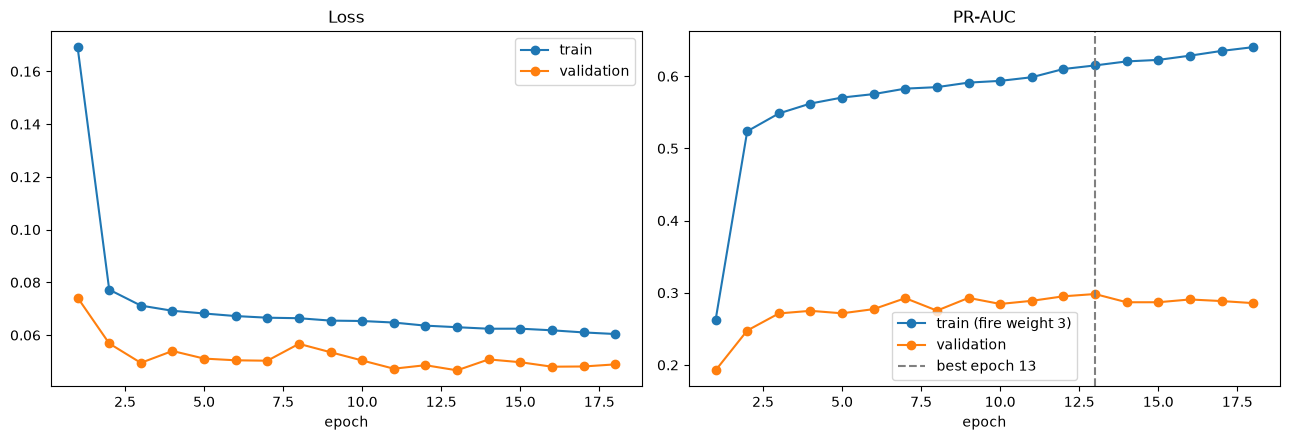

best epoch: 13 best validation PR-AUC: 0.2983


In [4]:
best_epoch = int(history_df["val_pr_auc"].idxmax())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(history_df.index, history_df["loss"], marker="o", label="train")
ax[0].plot(history_df.index, history_df["val_loss"], marker="o", label="validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("epoch")
ax[0].legend()
ax[1].plot(history_df.index, history_df["pr_auc"], marker="o", label="train (fire weight 3)")
ax[1].plot(history_df.index, history_df["val_pr_auc"], marker="o", label="validation")
ax[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch {best_epoch}")
ax[1].set_title("PR-AUC")
ax[1].set_xlabel("epoch")
ax[1].legend()
plt.tight_layout()
plt.savefig("results/figures/phase2/dl_training_curves.png", dpi=150)
plt.show()
print("best epoch:", best_epoch, "best validation PR-AUC:", round(history_df["val_pr_auc"].max(), 4))


## 5. Summary
- The U-Net has **491,553 parameters** and trained in about **31 minutes** on a laptop CPU (Apple M3).
- The best epoch was **13**, with **validation PR-AUC 0.298**. Validation fire rate is 1.37%, so this is about 22 times a random guess.
- Training PR-AUC keeps rising (0.64 at epoch 18) while validation stops at about 0.29–0.30. That gap is overfitting, so early stopping kept the epoch 13 weights. Training PR-AUC is also higher partly because fire pixels count 3 times there.
- Validation loss stays below training loss because dropout and augmentation are only active during training, and validation fire pixels are not weighted.
- The model is saved in `results/models/unet.keras` and the epoch-by-epoch numbers in `results/metrics/dl_training_history.csv`.